# Resilience Analysis

**Master's thesis:** From Dyads to Networks: Vendor Lock-in and Systemic Vulnerability in German Public IT Procurement

**Author:** Marco Stoehr

**Notebook:** 5 of 5 (run in order; see README)

**Thesis sections:** 3.4, 4.3

## Purpose
This notebook tests the network-level hypothesis (H4). For each CPV segment, the dyad-year data are aggregated into a bipartite buyer-supplier network for 2017–2023, restricted to buyers with at least two supplier relationships. Suppliers are then removed sequentially under three strategies:

1. **Lock-in targeted:** suppliers ranked by their number of locked-in buyers (dyads active in more than one year).
2. **Degree targeted:** suppliers ranked by their number of buyers, as a size-based benchmark.
3. **Random:** 100 iterations (seed 42), as a null reference.

After each removal, the share of isolated buyers and the size of the giant component are recorded.

## Input
- `data_analysis/`

## Main Output
- `graphs_tables/`: Illustrations of the findings
- `results/`: Latex-tables


In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from collections import defaultdict
import networkx as nx
from networkx.algorithms import bipartite
import gc
from scipy.stats import spearmanr

In [2]:
# settings
DATA = "data_analysis/"
MIN_BUYER_DEGREE = 2
segments = ["30", "48", "72"] 

# --- Load dyad-year data (only the columns needed here) ---
dyads = pd.read_csv(
    DATA + "dyad_years.csv",
    usecols=["YEAR", "cpv_segments_str", "CAE_NAME_CANONICAL", "WIN_NAME_FINAL"],
    dtype={
        "YEAR": "int16",
        "cpv_segments_str": "category",
        "CAE_NAME_CANONICAL": "category",
        "WIN_NAME_FINAL": "category",
    },
)
dyads_analysis = dyads[dyads["YEAR"].between(2017, 2023)].copy()
del dyads
gc.collect()

# --- Build aggregated bipartite adjacency per segment ---
networks = {}
for seg in segments:
    df_seg = dyads_analysis[dyads_analysis["cpv_segments_str"].str.contains(seg)]
    adj = defaultdict(set)
    for b, s in zip(df_seg["CAE_NAME_CANONICAL"], df_seg["WIN_NAME_FINAL"]):
        adj[b].add(s)

    # Buyers with a single supplier cannot be fragmented further; resilience
    # is only meaningful for buyers with multiple supplier relationships.
    adj_filtered = {b: s for b, s in adj.items() if len(s) >= MIN_BUYER_DEGREE}
    networks[seg] = adj_filtered

    n_suppliers = len(set().union(*adj_filtered.values()))
    print(f"CPV {seg}: {len(adj_filtered)} buyers (filtered from {len(adj)}), "
          f"{n_suppliers} suppliers, {sum(len(v) for v in adj_filtered.values())} edges")

del dyads_analysis, df_seg, adj, adj_filtered
gc.collect()

# --- Load lock-in profiles used for the targeted removal ranking ---
PROFILE_COLS = ["WIN_NAME_FINAL", "n_total_buyers", "n_locked_in_buyers",
                "mean_cumulative_ties", "n_captive_buyers", "captive_share", "lock_in_pct"]

# n_locked_in_buyers is a count with wide ties (up to 200 suppliers share one
# value), so it cannot order the ranking on its own: the remaining order would
# come from the row order of the CSV. mean_cumulative_ties breaks ties within
# the same lock-in logic, the supplier name makes the result reproducible.
RANK_KEYS = ["n_locked_in_buyers", "mean_cumulative_ties", "WIN_NAME_FINAL"]
RANK_ASC = [False, False, True]

lockin_profiles = {}
for seg in segments:
    path = DATA + f"supplier_lockin_profile_cpv{seg}.csv"
    lp = pd.read_csv(path, usecols=PROFILE_COLS)
    lp = lp.sort_values(RANK_KEYS, ascending=RANK_ASC).reset_index(drop=True)
    lockin_profiles[seg] = lp
    print(f"\nCPV {seg} loaded from {path}: {len(lp)} supplier rows")
    print(lp[["WIN_NAME_FINAL", "n_locked_in_buyers", "mean_cumulative_ties"]].head())

# --- Control: do profiles and filtered networks describe the same suppliers? ---
print("\n--- Profile / network coverage ---")
for seg in segments:
    net_sup = set().union(*networks[seg].values())
    prof_sup = set(lockin_profiles[seg]["WIN_NAME_FINAL"])
    missing = net_sup - prof_sup
    print(f"CPV {seg}: profile {len(prof_sup)} | network {len(net_sup)} | "
          f"network not in profile: {len(missing)} | "
          f"profile not in network: {len(prof_sup - net_sup)}")
    if missing:
        print("   examples:", sorted(missing)[:5])

CPV 30: 1369 buyers (filtered from 2353), 2058 suppliers, 6933 edges
CPV 48: 914 buyers (filtered from 2013), 2060 suppliers, 4789 edges
CPV 72: 933 buyers (filtered from 2116), 3856 suppliers, 7974 edges

CPV 30 loaded from data_analysis/supplier_lockin_profile_cpv30.csv: 2250 supplier rows
               WIN_NAME_FINAL  n_locked_in_buyers  mean_cumulative_ties
0                  Bechtle AG                 175              2.474227
1                   Cancom SE                  69              1.720000
2      Ricoh Deutschland GmbH                  62              2.000000
3     Lyreco Deutschland GmbH                  43              1.903226
4  Computacenter AG & Co. oHG                  33              2.626866

CPV 48 loaded from data_analysis/supplier_lockin_profile_cpv48.csv: 2355 supplier rows
                      WIN_NAME_FINAL  n_locked_in_buyers  mean_cumulative_ties
0                         Bechtle AG                  66              1.489796
1                           S

In [3]:
# define functions
ROLE_BUYER, ROLE_SUPPLIER = "B", "S"


def build_bipartite_graph(adj):
    """Build networkx bipartite graph from adjacency dict.

    Node ids are (role, name) tuples. A few organisations act as buyer and as
    supplier within the same segment; role-tagged ids keep those two network
    positions separate instead of collapsing them into a single node.
    """
    G = nx.Graph()
    for buyer, suppliers in adj.items():
        b_node = (ROLE_BUYER, buyer)
        G.add_node(b_node, bipartite=0)  # buyers = partition 0
        for supplier in suppliers:
            s_node = (ROLE_SUPPLIER, supplier)
            G.add_node(s_node, bipartite=1)  # suppliers = partition 1
            G.add_edge(b_node, s_node)
    return G


def get_buyers(G):
    """Return set of buyer nodes."""
    return {n for n, d in G.nodes(data=True) if d["bipartite"] == 0}


def get_suppliers(G):
    """Return set of supplier nodes."""
    return {n for n, d in G.nodes(data=True) if d["bipartite"] == 1}


def initial_active_size(G):
    """Number of nodes with at least one edge in the intact network.

    Used as the fixed denominator for the giant-component share so that the
    metric refers to the original network, not to whatever is left.
    """
    return sum(1 for n in G.nodes() if G.degree(n) > 0)


def compute_metrics(G, buyers, n_active_0, vuln_func=None):
    """Compute all resilience metrics from current graph state."""
    # Buyer isolation (degree 0 among buyer nodes)
    n_isolated = sum(1 for b in buyers if G.degree(b) == 0)

    # Component structure is computed on the subgraph of nodes that still have
    # at least one edge. Isolated buyers are already captured by n_isolated and
    # would otherwise inflate the component count by one each.
    active = [n for n in G.nodes() if G.degree(n) > 0]
    H = G.subgraph(active)
    components = list(nx.connected_components(H))

    n_components = len(components)
    gcc_size = max((len(c) for c in components), default=0)

    # Normalised against the INITIAL active network size, not the current one,
    # so the share is monotone and comparable across steps and strategies.
    gcc_frac = gcc_size / n_active_0 * 100 if n_active_0 else 0.0

    # Custom vulnerability function (optional, for alternative thresholds)
    n_vuln_custom = vuln_func(G, buyers) if vuln_func else None

    return {
        "n_isolated": n_isolated,
        "pct_isolated": n_isolated / len(buyers) * 100,
        "n_components": n_components,
        "gcc_size": gcc_size,
        "gcc_frac": gcc_frac,
        "n_vuln_custom": n_vuln_custom
    }


def simulate_targeted(G_original, removal_order, max_steps, vuln_func=None):
    """Targeted sequential removal with full metric tracking.

    removal_order holds plain supplier names; they are mapped to supplier-role
    node ids here, so the recorded results stay readable.
    """
    G = G_original.copy()
    buyers = get_buyers(G)
    n_active_0 = initial_active_size(G)

    results = [{"step": 0, "supplier_removed": None,
                **compute_metrics(G, buyers, n_active_0, vuln_func)}]

    steps = min(max_steps, len(removal_order))
    for i in range(steps):
        supplier = removal_order[i]
        node = (ROLE_SUPPLIER, supplier)
        if node in G:
            G.remove_node(node)
        results.append({"step": i + 1, "supplier_removed": supplier,
                        **compute_metrics(G, buyers, n_active_0, vuln_func)})
    return results


def simulate_random(G_original, max_steps, n_iterations, vuln_func=None, rng_seed=42):
    """Random removal baseline. Returns dict of metric arrays."""
    buyers = get_buyers(G_original)
    n_active_0 = initial_active_size(G_original)
    suppliers = sorted(get_suppliers(G_original))  # sorted: reproducible with seed
    rng = np.random.default_rng(rng_seed)

    # Pre-allocate arrays for each metric
    n_steps = max_steps + 1
    arrays = {
        "pct_isolated": np.zeros((n_iterations, n_steps)),
        "n_components": np.zeros((n_iterations, n_steps)),
        "gcc_frac": np.zeros((n_iterations, n_steps))
    }

    for it in range(n_iterations):
        G = G_original.copy()
        # Permute indices, not the node list: node ids are tuples and would be
        # turned into a 2D array by rng.permutation.
        order = rng.permutation(len(suppliers))

        m = compute_metrics(G, buyers, n_active_0, vuln_func)
        arrays["pct_isolated"][it, 0] = m["pct_isolated"]
        arrays["n_components"][it, 0] = m["n_components"]
        arrays["gcc_frac"][it, 0] = m["gcc_frac"]

        for step in range(max_steps):
            if step < len(order):
                node = suppliers[order[step]]
                if node in G:
                    G.remove_node(node)
            m = compute_metrics(G, buyers, n_active_0, vuln_func)
            arrays["pct_isolated"][it, step + 1] = m["pct_isolated"]
            arrays["n_components"][it, step + 1] = m["n_components"]
            arrays["gcc_frac"][it, step + 1] = m["gcc_frac"]

        del G
    return arrays

In [4]:
# --- Build bipartite graphs ---
graphs = {}
for seg in segments:
    graphs[seg] = build_bipartite_graph(networks[seg])
    print(f"CPV {seg}: {len(get_buyers(graphs[seg]))} buyers, "
          f"{len(get_suppliers(graphs[seg]))} suppliers, "
          f"{graphs[seg].number_of_edges()} edges, "
          f"{nx.number_connected_components(graphs[seg])} components")

# --- Build removal rankings ---
# All three strategies must draw from the same universe: the suppliers that
# still hold at least one edge after the buyer degree filter. Profile rows
# without edges would otherwise become no-op steps in the targeted strategy.
lockin_rankings = {}
degree_rankings = {}

for seg in segments:
    net_sup = {name for _, name in get_suppliers(graphs[seg])}

    lp = lockin_profiles[seg]
    in_net = lp["WIN_NAME_FINAL"].isin(net_sup)
    lockin_rankings[seg] = lp.loc[in_net, "WIN_NAME_FINAL"].tolist()

    dropped = lp.loc[~in_net]
    max_dropped = int(dropped["n_locked_in_buyers"].max()) if len(dropped) else 0
    print(f"CPV {seg}: lock-in ranking {len(lockin_rankings[seg])} suppliers, "
          f"{len(dropped)} profile rows dropped (no edges after buyer filter), "
          f"highest n_locked_in_buyers among dropped: {max_dropped}")

    supplier_degree = defaultdict(int)
    for buyer_suppliers in networks[seg].values():
        for s in buyer_suppliers:
            supplier_degree[s] += 1
    # Deterministic tiebreak by name so the ranking is reproducible.
    degree_rankings[seg] = [s for s, _ in sorted(supplier_degree.items(),
                                                 key=lambda x: (-x[1], x[0]))]

# --- Control: all three strategies operate on the same supplier universe ---
print("\n--- Removal universe per strategy ---")
for seg in segments:
    net_sup = {name for _, name in get_suppliers(graphs[seg])}
    print(f"CPV {seg}: network {len(net_sup)} | lock-in ranking "
          f"{len(lockin_rankings[seg])} | degree ranking {len(degree_rankings[seg])} | "
          f"identical sets: "
          f"{set(lockin_rankings[seg]) == net_sup == set(degree_rankings[seg])}")

# --- Run all three removal strategies ---
MAX_STEPS = 100
N_RANDOM_ITER = 100

targeted_results = {}
degree_targeted_results = {}
random_results = {}

for seg in segments:
    print(f"\n{'='*50}")
    print(f"CPV {seg}")
    print(f"{'='*50}")

    print("Running lock-in targeted removal...")
    targeted_results[seg] = simulate_targeted(graphs[seg], lockin_rankings[seg], MAX_STEPS)

    print("Running degree targeted removal...")
    degree_targeted_results[seg] = simulate_targeted(
        graphs[seg], degree_rankings[seg], MAX_STEPS)

    print(f"Running random removal ({N_RANDOM_ITER} iterations)...")
    random_results[seg] = simulate_random(graphs[seg], MAX_STEPS, N_RANDOM_ITER)

    t = targeted_results[seg][-1]
    d = degree_targeted_results[seg][-1]
    r_iso = random_results[seg]["pct_isolated"][:, -1].mean()
    r_gcc = random_results[seg]["gcc_frac"][:, -1].mean()
    r_comp = random_results[seg]["n_components"][:, -1].mean()
    print(f"After {MAX_STEPS} removals:")
    print(f"  Lock-in targeted: {t['pct_isolated']:.2f}% isolated, "
          f"GCC {t['gcc_frac']:.1f}%, {t['n_components']} components")
    print(f"  Degree targeted:  {d['pct_isolated']:.2f}% isolated, "
          f"GCC {d['gcc_frac']:.1f}%, {d['n_components']} components")
    print(f"  Random (mean):    {r_iso:.3f}% isolated, "
          f"GCC {r_gcc:.1f}%, {r_comp:.1f} components")

CPV 30: 1369 buyers, 2058 suppliers, 6933 edges, 46 components
CPV 48: 914 buyers, 2060 suppliers, 4789 edges, 67 components
CPV 72: 933 buyers, 3856 suppliers, 7974 edges, 93 components
CPV 30: lock-in ranking 2058 suppliers, 192 profile rows dropped (no edges after buyer filter), highest n_locked_in_buyers among dropped: 1
CPV 48: lock-in ranking 2060 suppliers, 295 profile rows dropped (no edges after buyer filter), highest n_locked_in_buyers among dropped: 1
CPV 72: lock-in ranking 3856 suppliers, 401 profile rows dropped (no edges after buyer filter), highest n_locked_in_buyers among dropped: 1

--- Removal universe per strategy ---
CPV 30: network 2058 | lock-in ranking 2058 | degree ranking 2058 | identical sets: True
CPV 48: network 2060 | lock-in ranking 2060 | degree ranking 2060 | identical sets: True
CPV 72: network 3856 | lock-in ranking 3856 | degree ranking 3856 | identical sets: True

CPV 30
Running lock-in targeted removal...
Running degree targeted removal...
Running 

In [5]:
# --- Verification 1: toy network with hand-computed expectations ---
# Edges: b1-s1, b1-s2, b2-s1, b2-s3, b3-s4, b3-s5  (3 buyers, 5 suppliers)
toy_adj = {
    "b1": {"s1", "s2"},
    "b2": {"s1", "s3"},
    "b3": {"s4", "s5"},
}
G_toy = build_bipartite_graph(toy_adj)
toy_res = simulate_targeted(G_toy, ["s1", "s2", "s4"], max_steps=3)

# Worked out by hand. 8 nodes carry an edge at step 0, so the GCC share is
# normalised on those 8 throughout:
#   step 0           : {b1,b2,s1,s2,s3} + {b3,s4,s5}      -> 2 comp, GCC 5/8
#   step 1 (drop s1) : {b1,s2} + {b2,s3} + {b3,s4,s5}     -> 3 comp, GCC 3/8
#   step 2 (drop s2) : b1 isolated; {b2,s3} + {b3,s4,s5}  -> 2 comp, GCC 3/8
#   step 3 (drop s4) : b1 isolated; {b2,s3} + {b3,s5}     -> 2 comp, GCC 2/8
toy_expected = [
    {"n_isolated": 0, "n_components": 2, "gcc_frac": 5 / 8 * 100},
    {"n_isolated": 0, "n_components": 3, "gcc_frac": 3 / 8 * 100},
    {"n_isolated": 1, "n_components": 2, "gcc_frac": 3 / 8 * 100},
    {"n_isolated": 1, "n_components": 2, "gcc_frac": 2 / 8 * 100},
]

print("--- Toy network: computed vs. expected ---")
for step, (exp, got) in enumerate(zip(toy_expected, toy_res)):
    match = all(abs(got[k] - exp[k]) < 1e-9 for k in exp)
    print(f"step {step}: isolated {got['n_isolated']}/{exp['n_isolated']} | "
          f"components {got['n_components']}/{exp['n_components']} | "
          f"GCC {got['gcc_frac']:.2f}/{exp['gcc_frac']:.2f} | match: {match}")

del G_toy, toy_res
gc.collect()

# --- Verification 2: step-0 baseline reproduced independently ---
# At step 0 every node carries an edge, so the GCC share must equal the largest
# component computed directly on the intact graph.
print("\n--- Step-0 baseline vs. direct computation ---")
for seg in segments:
    G = graphs[seg]
    ref_gcc = max(len(c) for c in nx.connected_components(G)) / G.number_of_nodes() * 100
    ref_comp = nx.number_connected_components(G)
    base_t = targeted_results[seg][0]
    base_d = degree_targeted_results[seg][0]
    base_r_iso = random_results[seg]["pct_isolated"][:, 0]
    base_r_gcc = random_results[seg]["gcc_frac"][:, 0]
    print(f"CPV {seg}: GCC {base_t['gcc_frac']:.4f} vs {ref_gcc:.4f} | "
          f"components {base_t['n_components']} vs {ref_comp} | "
          f"isolated at step 0: {base_t['n_isolated']} | "
          f"all strategies share baseline: "
          f"{abs(base_t['gcc_frac'] - base_d['gcc_frac']) < 1e-9 and
             np.allclose(base_r_gcc, base_t['gcc_frac']) and
             np.allclose(base_r_iso, base_t['pct_isolated'])}")

# --- Verification 3: monotonicity of the two cumulative metrics ---
# Removing nodes can never reconnect a buyer or grow the giant component.
# n_components is deliberately NOT checked: it rises during fragmentation and
# falls again once fragments disappear entirely (see toy steps 1 -> 2).
TOL = 1e-9
print("\n--- Monotonicity across removal steps ---")
for seg in segments:
    for label, res in [("lock-in", targeted_results[seg]),
                       ("degree ", degree_targeted_results[seg])]:
        iso = np.array([r["pct_isolated"] for r in res])
        gcc = np.array([r["gcc_frac"] for r in res])
        print(f"CPV {seg} {label}: isolation non-decreasing "
              f"{bool(np.all(np.diff(iso) >= -TOL))} | "
              f"GCC non-increasing {bool(np.all(np.diff(gcc) <= TOL))}")

    iso_r = random_results[seg]["pct_isolated"]
    gcc_r = random_results[seg]["gcc_frac"]
    print(f"CPV {seg} random : isolation non-decreasing "
          f"{bool(np.all(np.diff(iso_r, axis=1) >= -TOL))} | "
          f"GCC non-increasing {bool(np.all(np.diff(gcc_r, axis=1) <= TOL))} "
          f"(all {iso_r.shape[0]} iterations)")

--- Toy network: computed vs. expected ---
step 0: isolated 0/0 | components 2/2 | GCC 62.50/62.50 | match: True
step 1: isolated 0/0 | components 3/3 | GCC 37.50/37.50 | match: True
step 2: isolated 1/1 | components 2/2 | GCC 37.50/37.50 | match: True
step 3: isolated 1/1 | components 2/2 | GCC 25.00/25.00 | match: True

--- Step-0 baseline vs. direct computation ---
CPV 30: GCC 95.0978 vs 95.0978 | components 46 vs 46 | isolated at step 0: 0 | all strategies share baseline: True
CPV 48: GCC 91.5266 vs 91.5266 | components 67 vs 67 | isolated at step 0: 0 | all strategies share baseline: True
CPV 72: GCC 92.6707 vs 92.6707 | components 93 vs 93 | isolated at step 0: 0 | all strategies share baseline: True

--- Monotonicity across removal steps ---
CPV 30 lock-in: isolation non-decreasing True | GCC non-increasing True
CPV 30 degree : isolation non-decreasing True | GCC non-increasing True
CPV 30 random : isolation non-decreasing True | GCC non-increasing True (all 100 iterations)
CPV 

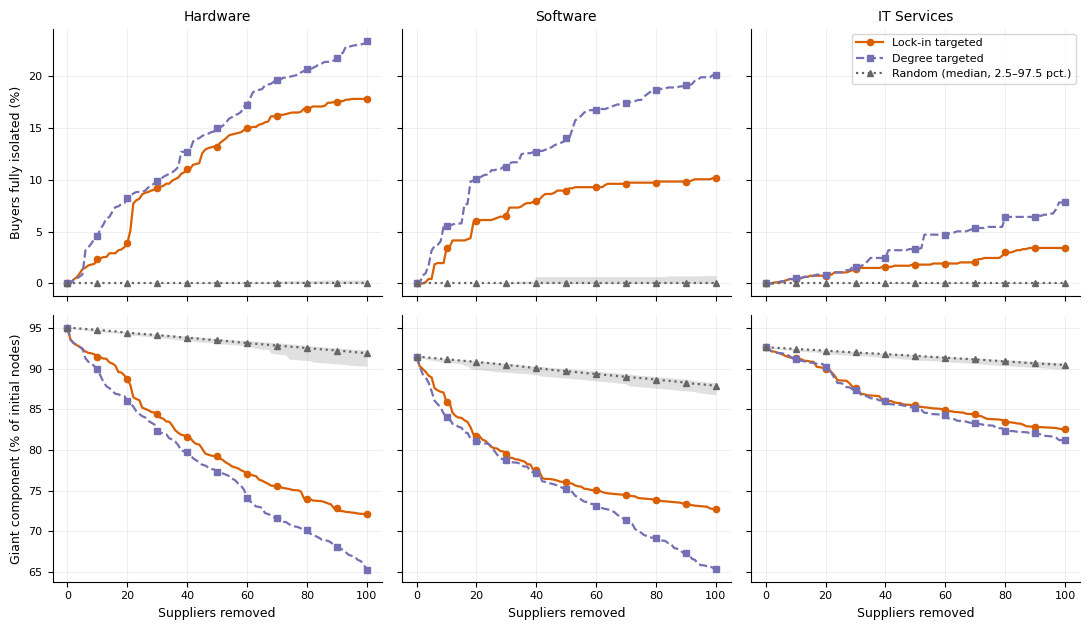

In [6]:
# plots

# Within a panel the series are the three removal strategies, so colour encodes
# the strategy; the segment is given by the column heading. Random removal is
# the null reference and is drawn in neutral grey. Line style and marker repeat
# the distinction for black-and-white print. Palette: ColorBrewer Dark2.
STRATEGY_STYLE = {
    "lockin": {"color": "#D95F02", "linestyle": "-",  "marker": "o",
               "label": "Lock-in targeted"},
    "degree": {"color": "#7570B3", "linestyle": "--", "marker": "s",
               "label": "Degree targeted"},
    "random": {"color": "#666666", "linestyle": ":",  "marker": "^",
               "label": "Random (median, 2.5–97.5 pct.)"},
}
seg_labels = {"30": "Hardware", "48": "Software",
              "72": "IT Services"}
metrics = [("pct_isolated", "Buyers fully isolated (%)"),
           ("gcc_frac", "Giant component (% of initial nodes)")]

steps = np.arange(MAX_STEPS + 1)
fig, axes = plt.subplots(len(metrics), len(segments), figsize=(11, 6.4),
                         sharex=True, sharey="row")

for col, seg in enumerate(segments):
    for row, (key, ylabel) in enumerate(metrics):
        ax = axes[row, col]
        # Labels are attached in the top-right panel, where the legend sits.
        legend_panel = (row == 0 and col == len(segments) - 1)

        for res, style_key in [(targeted_results[seg], "lockin"),
                               (degree_targeted_results[seg], "degree")]:
            st = STRATEGY_STYLE[style_key]
            ax.plot(steps, [r[key] for r in res], color=st["color"],
                    linestyle=st["linestyle"], marker=st["marker"],
                    markevery=10, markersize=4.5, linewidth=1.6,
                    label=st["label"] if legend_panel else None)

        rnd = random_results[seg][key]
        st = STRATEGY_STYLE["random"]
        ax.fill_between(steps, np.percentile(rnd, 2.5, axis=0),
                        np.percentile(rnd, 97.5, axis=0),
                        color=st["color"], alpha=0.20, linewidth=0)
        ax.plot(steps, np.median(rnd, axis=0), color=st["color"],
                linestyle=st["linestyle"], marker=st["marker"],
                markevery=10, markersize=4.5, linewidth=1.6,
                label=st["label"] if legend_panel else None)

        if row == 0:
            ax.set_title(seg_labels[seg], fontsize=10)
        if col == 0:
            ax.set_ylabel(ylabel, fontsize=9)
        if row == len(metrics) - 1:
            ax.set_xlabel("Suppliers removed", fontsize=9)
        ax.grid(True, linewidth=0.4, alpha=0.35)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.tick_params(labelsize=8)

axes[0, len(segments) - 1].legend(fontsize=8, loc="upper right", frameon=True,
                                  borderaxespad=0.4, handlelength=2.4)

fig.tight_layout()
for ext in ("pdf", "png"):
    fig.savefig(f"graphs_tables/fig_resilience_strategies.{ext}", dpi=300,
                bbox_inches="tight")
plt.show()
plt.close(fig)

In [7]:
# --- Tabular summary of the simulation (for reporting and cross-checking) ---
CHECKPOINTS = [0, 10, 25, 50, 75, 100]
checkpoints = [s for s in CHECKPOINTS if s <= MAX_STEPS]

for seg in segments:
    tgt = targeted_results[seg]
    deg = degree_targeted_results[seg]
    rnd_iso = random_results[seg]["pct_isolated"]
    rnd_gcc = random_results[seg]["gcc_frac"]
    rnd_comp = random_results[seg]["n_components"]
    n_sup = len(lockin_rankings[seg])

    iso_rows, str_rows = [], []
    for s in checkpoints:
        iso_l = tgt[s]["pct_isolated"]
        iso_d = deg[s]["pct_isolated"]
        iso_r_med = float(np.median(rnd_iso[:, s]))
        iso_r_mean = float(rnd_iso[:, s].mean())
        # Ratio on the random mean: the random median is exactly 0 for many
        # steps, which would make the ratio undefined rather than large.
        ratio = iso_l / iso_r_mean if iso_r_mean > 0 else np.nan

        iso_rows.append({
            "step": s,
            "pct_removed": s / n_sup * 100,
            "iso_lockin": iso_l,
            "iso_degree": iso_d,
            "iso_deg_minus_lock": iso_d - iso_l,
            "iso_rnd_med": iso_r_med,
            "iso_rnd_mean": iso_r_mean,
            "ratio_lock_rnd": ratio,
        })
        str_rows.append({
            "step": s,
            "gcc_lockin": tgt[s]["gcc_frac"],
            "gcc_degree": deg[s]["gcc_frac"],
            "gcc_rnd_med": float(np.median(rnd_gcc[:, s])),
            "comp_lockin": tgt[s]["n_components"],
            "comp_degree": deg[s]["n_components"],
            "comp_rnd_med": float(np.median(rnd_comp[:, s])),
        })

    print(f"\n=== CPV {seg} — buyer isolation (%) | {n_sup} suppliers in network ===")
    print(pd.DataFrame(iso_rows).set_index("step").round(3).to_string())
    print(f"--- CPV {seg} — network structure ---")
    print(pd.DataFrame(str_rows).set_index("step").round(2).to_string())

# --- Overlap of the two targeted rankings, to read the divergence against ---
print("\n=== Top-k overlap: lock-in ranking vs. degree ranking ===")
overlap_rows = []
for seg in segments:
    lk, dg = lockin_rankings[seg], degree_rankings[seg]
    row = {"segment": seg}
    for k in (10, 25, 50, 100):
        row[f"top{k}"] = len(set(lk[:k]) & set(dg[:k]))
    overlap_rows.append(row)
print(pd.DataFrame(overlap_rows).set_index("segment").to_string())


=== CPV 30 — buyer isolation (%) | 2058 suppliers in network ===
      pct_removed  iso_lockin  iso_degree  iso_deg_minus_lock  iso_rnd_med  iso_rnd_mean  ratio_lock_rnd
step                                                                                                    
0           0.000       0.000       0.000               0.000          0.0         0.000             NaN
10          0.486       2.411       4.602               2.191          0.0         0.001        3300.000
25          1.215       8.619       8.839               0.219          0.0         0.002        3933.333
50          2.430      13.221      15.047               1.826          0.0         0.015         905.000
75          3.644      16.508      20.015               3.506          0.0         0.044         376.667
100         4.859      17.823      23.375               5.551          0.0         0.070         254.167
--- CPV 30 — network structure ---
      gcc_lockin  gcc_degree  gcc_rnd_med  comp_lockin  com

In [8]:
# --- Reporting statistics for H4, read at the final removal step ---
rows = []
for seg in segments:
    n_buyers = len(get_buyers(graphs[seg]))
    n_sup = len(lockin_rankings[seg])
    iso_l = targeted_results[seg][-1]["pct_isolated"]
    iso_d = degree_targeted_results[seg][-1]["pct_isolated"]
    rnd = random_results[seg]["pct_isolated"][:, -1]

    rows.append({
        "segment": seg,
        "buyers": n_buyers,
        "pct_removed": MAX_STEPS / n_sup * 100,
        "n_iso_lockin": iso_l / 100 * n_buyers,
        "n_iso_degree": iso_d / 100 * n_buyers,
        "n_iso_rnd_mean": rnd.mean() / 100 * n_buyers,
        "n_iso_rnd_max": rnd.max() / 100 * n_buyers,
        "ratio_lockin": iso_l / rnd.mean() if rnd.mean() > 0 else np.nan,
        "ratio_degree": iso_d / rnd.mean() if rnd.mean() > 0 else np.nan,
        # How many of the random iterations reach the targeted damage at all?
        "rnd_iters_reaching_lockin": int((rnd >= iso_l).sum()),
        "rnd_iters_reaching_degree": int((rnd >= iso_d).sum()),
    })

print(pd.DataFrame(rows).set_index("segment").round(2).to_string())

         buyers  pct_removed  n_iso_lockin  n_iso_degree  n_iso_rnd_mean  n_iso_rnd_max  ratio_lockin  ratio_degree  rnd_iters_reaching_lockin  rnd_iters_reaching_degree
segment                                                                                                                                                                  
30         1369         4.86         244.0         320.0            0.96           10.0        254.17        333.33                          0                          0
48          914         4.85          93.0         184.0            1.15           21.0         80.87        160.00                          0                          0
72          933         2.59          32.0          73.0            0.16            2.0        200.00        456.25                          0                          0


In [9]:
# --- Results table (LaTeX) for the resilience simulation ---
SEG_LABEL_TEX = {"30": "CPV 30 (hardware)", "48": "CPV 48 (software)",
                 "72": "CPV 72 (IT services)"}
STRATEGY_LABEL_TEX = {"base": "Before removal", "lockin": "Lock-in targeted",
                      "degree": "Degree targeted", "random": "Random (mean)"}

body, removed_shares = [], []
for seg in segments:
    n_buyers = len(get_buyers(graphs[seg]))
    removed_shares.append(MAX_STEPS / len(lockin_rankings[seg]) * 100)

    base = targeted_results[seg][0]
    t = targeted_results[seg][-1]
    d = degree_targeted_results[seg][-1]
    rnd = random_results[seg]
    r_iso = rnd["pct_isolated"][:, -1].mean()
    r_gcc = rnd["gcc_frac"][:, -1].mean()
    r_cmp = rnd["n_components"][:, -1].mean()

    header = f"{SEG_LABEL_TEX[seg]}, {n_buyers:,} buyers".replace(",", "{,}")
    body.append(f"\\multicolumn{{4}}{{l}}{{\\textit{{{header}}}}} \\\\")
    body.append(f"\\quad {STRATEGY_LABEL_TEX['base']} & {base['pct_isolated']:.1f} & "
                f"{base['gcc_frac']:.1f} & {base['n_components']:.0f} \\\\")
    body.append(f"\\quad {STRATEGY_LABEL_TEX['lockin']} & {t['pct_isolated']:.1f} & "
                f"{t['gcc_frac']:.1f} & {t['n_components']:.0f} \\\\")
    body.append(f"\\quad {STRATEGY_LABEL_TEX['degree']} & {d['pct_isolated']:.1f} & "
                f"{d['gcc_frac']:.1f} & {d['n_components']:.0f} \\\\")
    body.append(f"\\quad {STRATEGY_LABEL_TEX['random']} & {r_iso:.1f} & "
                f"{r_gcc:.1f} & {r_cmp:.0f} \\\\")
    if seg != segments[-1]:
        body.append("\\addlinespace")

share_note = " / ".join(f"{s:.1f}\\%" for s in removed_shares)
tex = "\n".join([
    r"\begin{table}[htbp]",
    r"\centering",
    r"\begin{threeparttable}",
    r"\caption{Network resilience after removal of 100 suppliers}",
    r"\label{tab:resilience}",
    r"\begin{tabular}{lrrr}",
    r"\toprule",
    r"Removal strategy & Isolated buyers (\%) & Giant component (\%) & Components \\",
    r"\midrule",
    *body,
    r"\bottomrule",
    r"\end{tabular}",
    r"\begin{tablenotes}[flushleft]\footnotesize",
    r"\item \textit{Notes.} Aggregated bipartite buyer--supplier networks, "
    r"2017--2023, restricted to buyers with at least two supplier relationships. "
    r"Suppliers are removed sequentially; the table reports the state after 100 "
    rf"removals, corresponding to {share_note} of the suppliers in the respective "
    r"segment. Isolated buyers are buyers left without any supplier relationship. "
    r"The giant component is expressed as a share of all nodes carrying an edge "
    r"in the intact network, so values are comparable across removal steps.",
    r"\item Random removal is averaged over 100 iterations. In no segment did any "
    r"iteration reach the damage of either targeted strategy.",
    r"\end{tablenotes}",
    r"\end{threeparttable}",
    r"\end{table}",
])

out_path = "results/tab_resilience.tex"
with open(out_path, "w", encoding="utf-8") as f:
    f.write(tex + "\n")
print(f"written: {out_path}\n")
print(tex)

written: results/tab_resilience.tex

\begin{table}[htbp]
\centering
\begin{threeparttable}
\caption{Network resilience after removal of 100 suppliers}
\label{tab:resilience}
\begin{tabular}{lrrr}
\toprule
Removal strategy & Isolated buyers (\%) & Giant component (\%) & Components \\
\midrule
\multicolumn{4}{l}{\textit{CPV 30 (hardware){,} 1{,}369 buyers}} \\
\quad Before removal & 0.0 & 95.1 & 46 \\
\quad Lock-in targeted & 17.8 & 72.1 & 205 \\
\quad Degree targeted & 23.4 & 65.2 & 246 \\
\quad Random (mean) & 0.1 & 91.9 & 52 \\
\addlinespace
\multicolumn{4}{l}{\textit{CPV 48 (software){,} 914 buyers}} \\
\quad Before removal & 0.0 & 91.5 & 67 \\
\quad Lock-in targeted & 10.2 & 72.7 & 195 \\
\quad Degree targeted & 20.1 & 65.3 & 221 \\
\quad Random (mean) & 0.1 & 87.8 & 74 \\
\addlinespace
\multicolumn{4}{l}{\textit{CPV 72 (IT services){,} 933 buyers}} \\
\quad Before removal & 0.0 & 92.7 & 93 \\
\quad Lock-in targeted & 3.4 & 82.5 & 193 \\
\quad Degree targeted & 7.8 & 81.2 & 203 \\
\

In [10]:
# --- Diagnostic: is the lock-in ranking still informative at step 100? ---
print("--- Discriminatory power of n_locked_in_buyers along the ranking ---")
for seg in segments:
    lp = lockin_profiles[seg]
    lp_net = lp[lp["WIN_NAME_FINAL"].isin(set(lockin_rankings[seg]))]
    vals = lp_net["n_locked_in_buyers"].to_numpy()  # already sorted descending
    n_pos = int((vals > 0).sum())
    at = {r: (int(vals[r - 1]) if r <= len(vals) else None) for r in (10, 25, 50, 100)}
    # How many suppliers share the criterion value found at rank 100?
    tie_val = vals[99] if len(vals) >= 100 else None
    n_tied = int((vals == tie_val).sum()) if tie_val is not None else 0
    print(f"CPV {seg}: {n_pos} of {len(vals)} suppliers with n_locked_in_buyers > 0 | "
          f"value at rank 10/25/50/100: {at[10]}/{at[25]}/{at[50]}/{at[100]} | "
          f"suppliers tied at the rank-100 value: {n_tied}")

--- Discriminatory power of n_locked_in_buyers along the ranking ---
CPV 30: 404 of 2058 suppliers with n_locked_in_buyers > 0 | value at rank 10/25/50/100: 19/11/4/2 | suppliers tied at the rank-100 value: 50
CPV 48: 267 of 2060 suppliers with n_locked_in_buyers > 0 | value at rank 10/25/50/100: 11/5/2/1 | suppliers tied at the rank-100 value: 203
CPV 72: 794 of 3856 suppliers with n_locked_in_buyers > 0 | value at rank 10/25/50/100: 21/11/4/2 | suppliers tied at the rank-100 value: 73


In [11]:
# --- Diagnostic: agreement between the lock-in and the degree ranking ---
print("--- Rank agreement: n_locked_in_buyers vs degree ---")

K_VALUES = (10, 25, 50, 100)
overlap_rows = []

for seg in segments:
    lock_rank = list(lockin_rankings[seg])
    deg_rank = list(degree_rankings[seg])
    deg_pos = {s: i for i, s in enumerate(deg_rank)}

    # Guard instead of an assert: report rather than fail if the universes differ
    same_universe = set(lock_rank) == set(deg_pos)
    common = [s for s in lock_rank if s in deg_pos]

    rho = spearmanr(
        [i for i, s in enumerate(lock_rank) if s in deg_pos],
        [deg_pos[s] for s in common],
    ).statistic

    row = {
        "segment": seg,
        "n_universe": len(lock_rank),
        "same_universe": same_universe,
        "spearman_rank": round(float(rho), 3),
    }
    for k in K_VALUES:
        row[f"overlap_top{k}"] = len(set(lock_rank[:k]) & set(deg_rank[:k]))
    overlap_rows.append(row)

    ov = " | ".join(f"top-{k}: {row[f'overlap_top{k}']}/{k}" for k in K_VALUES)
    flag = "" if same_universe else "  [WARNING: universes differ]"
    print(f"CPV {seg}: n={row['n_universe']} | Spearman(rank, rank)="
          f"{row['spearman_rank']:+.3f} | {ov}{flag}")

rank_overlap = pd.DataFrame(overlap_rows)

--- Rank agreement: n_locked_in_buyers vs degree ---
CPV 30: n=2058 | Spearman(rank, rank)=+0.705 | top-10: 6/10 | top-25: 21/25 | top-50: 37/50 | top-100: 67/100
CPV 48: n=2060 | Spearman(rank, rank)=+0.630 | top-10: 8/10 | top-25: 15/25 | top-50: 30/50 | top-100: 53/100
CPV 72: n=3856 | Spearman(rank, rank)=+0.632 | top-10: 9/10 | top-25: 20/25 | top-50: 36/50 | top-100: 63/100
